# 19장. 평가 지표와 혼동 행렬

| 항목 | 내용 |
|---|---|
| 예상 시간 | 3시간 |
| 선수 장 | 6장 (히트맵), 18장 |
| 이 장의 결과물 | 정확도·F1, `classification_report`, 혼동 행렬 그림(`confusion_matrix.png`), 결과 해석 |
| 과제 연결 | "정확도, F1-Score를 측정하고 혼동 행렬을 시각화한다" |

**학습 목표**
- 정확도만 보면 안 되는 경우를 예로 들 수 있다.
- 혼동 행렬의 행과 열을 읽고, 어떤 카테고리끼리 헷갈리는지 말할 수 있다.
- 혼동 행렬에서 precision, recall, F1을 손으로 계산할 수 있다.
- macro 평균과 weighted 평균의 차이를 안다.
- 혼동 행렬을 그림으로 저장하고, 결과를 과제 형식으로 보고할 수 있다.

In [1]:
# ── 7장에서 만든 데이터 로딩 코드 (src/data.py로 옮길 내용) ──
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

PROJECT = Path.cwd().parent if Path.cwd().name == "studys" else Path.cwd()
RANDOM_STATE = 42
EN_CATEGORIES = ["comp.graphics", "comp.windows.x", "rec.sport.baseball", "rec.sport.hockey", "sci.space"]
YNAT_URL = ("https://raw.githubusercontent.com/KLUE-benchmark/KLUE/main/"
            "klue_benchmark/ynat-v1.1/ynat-v1.1_train.json")
YNAT_PATH = PROJECT / "data" / "raw" / "ynat-v1.1_train.json"

_EMAIL = re.compile(r"\S+@\S+\.\S+")
_URL = re.compile(r"(https?://|www\.)\S+")
_PHONE = re.compile(r"\b\d{2,4}[-.\s]\d{3,4}[-.\s]\d{4}\b")


def mask_pii(text: str) -> str:
    text = _EMAIL.sub(" <email> ", text)
    text = _URL.sub(" <url> ", text)
    return _PHONE.sub(" <phone> ", text)


def finalize(df: pd.DataFrame) -> pd.DataFrame:
    """개인정보 가리기 → 빈 문서 제거 → 레이블 충돌 중복·중복 제거 → 인덱스 재정렬."""
    df = df.assign(text=df["text"].map(mask_pii).str.strip())
    df = df[df["text"] != ""]
    norm = df["text"].str.split().str.join(" ")
    conflict = df.groupby(norm)["label"].transform("nunique") > 1
    df, norm = df[~conflict], norm[~conflict]
    return df[~norm.duplicated(keep="first")].reset_index(drop=True)


def load_english() -> pd.DataFrame:
    bunch = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES,
                               remove=("headers", "footers", "quotes"),
                               shuffle=True, random_state=RANDOM_STATE)
    labels = [bunch.target_names[t] for t in bunch.target]
    return finalize(pd.DataFrame({"text": bunch.data, "label": labels}))


def load_korean(per_class: int = 1000) -> pd.DataFrame:
    if not YNAT_PATH.exists():
        YNAT_PATH.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(YNAT_URL, YNAT_PATH)
    raw = pd.read_json(YNAT_PATH).rename(columns={"title": "text"})[["guid", "text", "label"]]
    sampled = (raw.groupby("label", group_keys=False)
                  .sample(n=per_class, random_state=RANDOM_STATE)
                  .sample(frac=1.0, random_state=RANDOM_STATE))
    return finalize(sampled.reset_index(drop=True))

# ── 8~10장에서 만든 전처리 파이프라인 (src/preprocess.py로 옮길 내용) ──
from konlpy.tag import Okt
from nltk.corpus import stopwords

PLACEHOLDER = re.compile(r"<(?:email|url|phone)>")
EN_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")
KO_CLEAN = re.compile(r"[^0-9a-zA-Z가-힣一-鿿\s]")
HANJA_ONLY = re.compile(r"^[一-鿿]+$")
KO_KEEP_POS = {"Noun", "Verb", "Adjective", "Alpha"}
EN_STOP = frozenset(stopwords.words("english"))
DOMAIN_STOPWORDS_EN = frozenset({
    "would", "could", "might", "may", "also", "like", "get", "got", "go", "going", "know", "think",
    "see", "say", "make", "want", "look", "one", "well", "much", "many", "even", "way", "something",
    "anyone", "since", "still", "really", "right", "another", "cant",
})
STOPWORDS_KO = frozenset({
    "하다", "되다", "있다", "없다", "이다", "않다",
    "등", "것", "수", "중", "및", "때", "후", "내", "듯", "제", "개", "의", "로", "종합",
})
_okt = Okt()


def clean_en(text: str) -> str:
    text = PLACEHOLDER.sub(" ", text.lower()).replace("’", "'")
    return " ".join(EN_TOKEN.findall(text))


def clean_ko(text: str) -> str:
    return " ".join(KO_CLEAN.sub(" ", PLACEHOLDER.sub(" ", text)).split())


class EnglishPreprocessor:
    def __init__(self, use_domain_stopwords: bool = True, min_len: int = 2, max_len: int = 20):
        self.stopwords = EN_STOP | (DOMAIN_STOPWORDS_EN if use_domain_stopwords else frozenset())
        self.min_len, self.max_len = min_len, max_len

    def __call__(self, text: str) -> list[str]:
        tokens = []
        for tok in clean_en(text).split():
            if tok in self.stopwords:
                continue
            tok = tok.removesuffix("'s").replace("'", "")
            if self.min_len <= len(tok) <= self.max_len and tok not in self.stopwords:
                tokens.append(tok)
        return tokens


class KoreanPreprocessor:
    def __init__(self, tokenizer: str = "okt", use_stopwords: bool = True):
        if tokenizer not in ("okt", "whitespace"):
            raise ValueError(f"tokenizer는 'okt' 또는 'whitespace': {tokenizer}")
        self.tokenizer = tokenizer
        self.stopwords = STOPWORDS_KO if use_stopwords else frozenset()

    def tokenize(self, text: str) -> list[str]:
        if self.tokenizer == "whitespace":
            return clean_ko(text).lower().split()
        return [w.lower() for w, p in _okt.pos(clean_ko(text), norm=True, stem=True)
                if p in KO_KEEP_POS or (p == "Foreign" and HANJA_ONLY.match(w))]

    def __call__(self, text: str) -> list[str]:
        return [t for t in self.tokenize(text) if t not in self.stopwords and not t.isdigit()]

# ── 로드 + 전처리를 한 번에 (src/corpus.py로 옮길 내용) ──
MIN_TOKENS = {"en": 5, "ko": 2}   # 전처리 후 토큰이 이보다 적은 문서는 뺀다 (짧은 답글, 주제어 없는 제목)
MIN_DF = {"en": 3, "ko": 2}       # 어휘에 넣을 최소 문서 빈도 (11장)


def load_corpus(lang: str, tokenizer: str = "okt") -> pd.DataFrame:
    """열: text, label, tokens. lang은 "en" 또는 "ko"."""
    df = load_english() if lang == "en" else load_korean()
    prep = EnglishPreprocessor() if lang == "en" else KoreanPreprocessor(tokenizer)
    df["tokens"] = [prep(t) for t in df["text"]]
    df = df[df["tokens"].map(len) >= MIN_TOKENS[lang]].reset_index(drop=True)
    df.attrs["preprocessor"] = prep
    return df

# ── 13장에서 만든 NumPy TF-IDF (src/tfidf.py로 옮길 내용) ──
class NumpyTfidf:
    """TF(raw 또는 log) × smooth IDF, 문서마다 L2 정규화. sklearn TfidfVectorizer와 같은 정의."""

    def __init__(self, tf: str = "raw", smooth_idf: bool = True, norm: str | None = "l2",
                 min_df: int = 1, max_df: float = 1.0):
        if tf not in ("raw", "log"):
            raise ValueError(f"tf는 'raw' 또는 'log': {tf}")
        if norm not in ("l2", None):
            raise ValueError(f"norm은 'l2' 또는 None: {norm}")
        self.tf, self.smooth_idf, self.norm = tf, smooth_idf, norm
        self.min_df, self.max_df = min_df, max_df

    def fit(self, docs: list[list[str]]) -> "NumpyTfidf":
        n = len(docs)
        df: dict[str, int] = {}
        for doc in docs:
            for t in set(doc):
                df[t] = df.get(t, 0) + 1
        max_count = self.max_df * n if isinstance(self.max_df, float) else self.max_df
        terms = sorted(t for t, c in df.items() if self.min_df <= c <= max_count)
        self.vocabulary_ = {t: i for i, t in enumerate(terms)}
        self.terms_ = np.array(terms, dtype=object)
        self.n_docs_ = n
        self.df_ = np.array([df[t] for t in terms], dtype=np.float64)
        if self.smooth_idf:
            self.idf_ = np.log((1.0 + n) / (1.0 + self.df_)) + 1.0
        else:
            self.idf_ = np.log(n / self.df_) + 1.0
        return self

    def count_matrix(self, docs: list[list[str]]) -> np.ndarray:
        rows, cols = [], []
        for i, doc in enumerate(docs):
            for t in doc:
                j = self.vocabulary_.get(t)
                if j is not None:
                    rows.append(i)
                    cols.append(j)
        counts = np.zeros((len(docs), len(self.vocabulary_)), dtype=np.float64)
        np.add.at(counts, (np.asarray(rows, dtype=np.int64), np.asarray(cols, dtype=np.int64)), 1.0)
        return counts

    def transform(self, docs: list[list[str]]) -> np.ndarray:
        x = self.count_matrix(docs)
        if self.tf == "log":
            mask = x > 0
            x[mask] = 1.0 + np.log(x[mask])
        x *= self.idf_                                   # (n, V) * (V,) 브로드캐스팅
        if self.norm == "l2":
            norms = np.linalg.norm(x, axis=1, keepdims=True)
            x /= np.where(norms > 0, norms, 1.0)          # 빈 문서는 0 벡터로 둔다
        return x

    def fit_transform(self, docs: list[list[str]]) -> np.ndarray:
        return self.fit(docs).transform(docs)

# ── 17장에서 만든 분할·분류 코드 (src/classify.py로 옮길 내용) ──
from types import SimpleNamespace

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split


def split(corpus: pd.DataFrame, seed: int = RANDOM_STATE) -> tuple[pd.DataFrame, pd.DataFrame]:
    train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=seed)
    return train.reset_index(drop=True), test.reset_index(drop=True)


def run_classification(corpus: pd.DataFrame, lang: str, seed: int = RANDOM_STATE, C: float = 1.0):
    """Train으로만 TF-IDF를 fit하고, 로지스틱 회귀를 학습해 Test로 평가한다."""
    train, test = split(corpus, seed)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    X_train = vec.fit_transform(train["tokens"].tolist())
    X_test = vec.transform(test["tokens"].tolist())
    model = LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE).fit(X_train, train["label"])
    y_pred = model.predict(X_test)
    return SimpleNamespace(
        train=train, test=test, vec=vec, model=model, X_train=X_train, X_test=X_test,
        y_pred=y_pred, labels=list(model.classes_), proba=model.predict_proba(X_test),
        accuracy=accuracy_score(test["label"], y_pred),
        f1_macro=f1_score(test["label"], y_pred, average="macro"),
    )

# ── 6장에서 만든 한글 글꼴 설정 ──
import matplotlib.pyplot as plt
from matplotlib import font_manager


def set_korean_font() -> str | None:
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            plt.rcParams["axes.unicode_minus"] = False
            return name
    return None

import tempfile

import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

WORK = Path(tempfile.mkdtemp())   # 그림은 임시 폴더에 저장한다 (실제 프로젝트는 outputs/)
en = load_corpus("en")
ko = load_corpus("ko")
ko_ws = load_corpus("ko", tokenizer="whitespace")
res = {"en": run_classification(en, "en"),
       "ko-okt": run_classification(ko, "ko"),
       "ko-whitespace": run_classification(ko_ws, "ko")}
for name, r in res.items():
    print(f"{name:<14} 정확도 {r.accuracy:.3f}  macro F1 {r.f1_macro:.3f}")

en             정확도 0.900  macro F1 0.900
ko-okt         정확도 0.770  macro F1 0.770
ko-whitespace  정확도 0.706  macro F1 0.710


## 19.1 정확도와 그 함정

**정확도(accuracy)** = 맞힌 문서 수 ÷ 전체 문서 수. 가장 직관적이지만, 카테고리 크기가 크게 다르면 속을 수 있습니다.

예: 스팸 메일 100통 중 5통만 스팸이라고 합시다. **무조건 "정상"이라고 답하는** 모델도 정확도 0.95를 얻습니다. 하지만 스팸은 하나도 못 잡습니다.

In [2]:
y_true = ["정상"] * 95 + ["스팸"] * 5
y_lazy = ["정상"] * 100

p, r, f, n = precision_recall_fscore_support(y_true, y_lazy, labels=["정상", "스팸"], zero_division=0)
print(f"정확도: {accuracy_score(y_true, y_lazy):.2f}")
print(pd.DataFrame({"precision": p, "recall": r, "F1": f, "문서 수": n}, index=["정상", "스팸"]).round(2))
print(f"macro F1: {f1_score(y_true, y_lazy, average='macro', zero_division=0):.2f}")

정확도: 0.95
    precision  recall    F1  문서 수
정상       0.95     1.0  0.97    95
스팸       0.00     0.0  0.00     5
macro F1: 0.49


정확도는 0.95지만 스팸의 recall과 F1은 0이고, macro F1은 약 0.49입니다. 그래서 과제도 정확도와 함께 **F1**을 요구합니다. 이 과제의 데이터는 카테고리가 고르게 뽑혀 있어 정확도와 macro F1이 비슷하게 나오지만, 카테고리별 성능 차이는 따로 봐야 보입니다.

## 19.2 혼동 행렬 읽기

**혼동 행렬(confusion matrix)**은 "실제 × 예측" 표입니다.
- **행** = 실제 카테고리, **열** = 예측 카테고리
- **대각선** = 맞힌 개수, **대각선 밖** = 틀린 개수와 그 방향
- 행 합계 = 그 카테고리의 실제 문서 수, 열 합계 = 그 카테고리로 예측된 문서 수

In [3]:
r_en = res["en"]
cm_en = confusion_matrix(r_en.test["label"], r_en.y_pred, labels=r_en.labels)
short = [lab.split(".", 1)[1] if lab.startswith("comp.") else lab.split(".")[-1] for lab in r_en.labels]  # comp.windows.x → windows.x
cm_df = pd.DataFrame(cm_en, index=[f"실제 {s}" for s in short], columns=[f"예측 {s}" for s in short])
cm_df

,예측 graphics,예측 windows.x,예측 baseball,예측 hockey,예측 space
실제 graphics,161,11,3,0,10
실제 windows.x,27,159,0,0,1
실제 baseball,4,1,165,9,3
실제 hockey,0,2,3,176,8
실제 space,7,1,3,0,176


In [4]:
def top_confusions(cm, labels, k=5):
    pairs = [(int(cm[i, j]), labels[i], labels[j]) for i in range(len(labels)) for j in range(len(labels)) if i != j]
    return sorted(pairs, reverse=True)[:k]


n_err = cm_en.sum() - np.trace(cm_en)
print(f"영어 Test {cm_en.sum()}건 중 오분류 {n_err}건. 가장 많이 헷갈린 방향:")
for n, a, b in top_confusions(cm_en, short):
    print(f"  실제 {a:<9} → 예측 {b:<9} {n:>3}건")
gw = cm_en[short.index("graphics"), short.index("windows.x")] + cm_en[short.index("windows.x"), short.index("graphics")]
print(f"graphics ↔ windows.x 합계 {gw}건 = 전체 오분류의 {gw / n_err:.0%}")

영어 Test 930건 중 오분류 93건. 가장 많이 헷갈린 방향:
  실제 windows.x → 예측 graphics   27건
  실제 graphics  → 예측 windows.x  11건
  실제 graphics  → 예측 space      10건
  실제 baseball  → 예측 hockey      9건
  실제 hockey    → 예측 space       8건
graphics ↔ windows.x 합계 38건 = 전체 오분류의 41%


## 19.3 Precision, Recall, F1 ⭐

카테고리 $c$ 하나에 대해, 혼동 행렬에서 세 숫자를 읽습니다.

| 기호 | 뜻 | 혼동 행렬에서 |
|---|---|---|
| **TP** (True Positive) | 실제 $c$를 $c$로 맞힘 | 대각선 칸 |
| **FP** (False Positive) | 다른 카테고리를 $c$로 잘못 예측 | $c$ **열**에서 대각선을 뺀 합 |
| **FN** (False Negative) | 실제 $c$를 다른 것으로 예측 | $c$ **행**에서 대각선을 뺀 합 |

$$\text{precision} = \frac{TP}{TP + FP} \qquad \text{recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

- **precision(정밀도)**: "$c$라고 예측한 것 중 진짜 $c$의 비율". 검색 결과가 얼마나 깨끗한가.
- **recall(재현율)**: "진짜 $c$ 중 찾아낸 비율". 놓친 것이 얼마나 적은가.
- **F1**: 둘의 조화평균. 한쪽만 높고 다른 쪽이 낮으면 F1이 낮게 나옵니다.

혼동 행렬에서 직접 계산하고 sklearn 값과 대조합니다.

In [5]:
tp = np.diag(cm_en)
fp = cm_en.sum(axis=0) - tp          # 열 합 - 대각선
fn = cm_en.sum(axis=1) - tp          # 행 합 - 대각선
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

sk_p, sk_r, sk_f, support = precision_recall_fscore_support(r_en.test["label"], r_en.y_pred, labels=r_en.labels)
table = pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "precision": precision, "recall": recall, "F1": f1,
                      "sklearn F1": sk_f}, index=short)
print("직접 계산 == sklearn:", np.allclose(precision, sk_p) and np.allclose(recall, sk_r) and np.allclose(f1, sk_f))
table.round(3)

직접 계산 == sklearn: True


,TP,FP,FN,precision,recall,F1,sklearn F1
graphics,161,38,24,0.809,0.870,0.839,0.839
windows.x,159,15,28,0.914,0.850,0.881,0.881
baseball,165,9,17,0.948,0.907,0.927,0.927
hockey,176,9,13,0.951,0.931,0.941,0.941
space,176,22,11,0.889,0.941,0.914,0.914


## 19.4 macro 평균과 weighted 평균

카테고리별 F1을 하나의 숫자로 요약하는 방법이 여러 가지입니다.

| 평균 | 계산 | 특징 |
|---|---|---|
| **macro** | 카테고리별 F1의 단순 평균 | 모든 카테고리를 똑같이 중요하게 본다. **작은 카테고리의 실패가 그대로 드러남** |
| **weighted** | 카테고리 문서 수로 가중 평균 | 큰 카테고리의 영향이 크다 |
| micro | 전체 TP, FP, FN을 합쳐서 계산 | 단일 레이블 분류에서는 **정확도와 같다** |

In [6]:
y_t, y_p = r_en.test["label"], r_en.y_pred
print(f"macro F1    직접 {f1.mean():.4f} | sklearn {f1_score(y_t, y_p, average='macro'):.4f}")
print(f"weighted F1 직접 {np.average(f1, weights=support):.4f} | sklearn {f1_score(y_t, y_p, average='weighted'):.4f}")
print(f"micro F1         {f1_score(y_t, y_p, average='micro'):.4f} = 정확도 {accuracy_score(y_t, y_p):.4f}")

macro F1    직접 0.9004 | sklearn 0.9004
weighted F1 직접 0.9004 | sklearn 0.9004
micro F1         0.9000 = 정확도 0.9000


이 데이터는 카테고리 크기가 거의 같아서 세 값이 비슷합니다. 과제 결과 예시가 **F1-Score (macro)**를 쓰므로 이 자료도 macro F1을 기본으로 보고합니다.

## 19.5 `classification_report`

카테고리별 precision, recall, F1과 평균을 한 번에 보여 줍니다. `support`는 각 카테고리의 실제 문서 수입니다.

In [7]:
for name in ["en", "ko-okt"]:
    r = res[name]
    print(f"=== {name} ===")
    print(classification_report(r.test["label"], r.y_pred, digits=3))

=== en ===
                    precision    recall  f1-score   support

     comp.graphics      0.809     0.870     0.839       185
    comp.windows.x      0.914     0.850     0.881       187
rec.sport.baseball      0.948     0.907     0.927       182
  rec.sport.hockey      0.951     0.931     0.941       189
         sci.space      0.889     0.941     0.914       187

          accuracy                          0.900       930
         macro avg      0.902     0.900     0.900       930
      weighted avg      0.902     0.900     0.900       930

=== ko-okt ===
              precision    recall  f1-score   support

        IT과학      0.738     0.815     0.774       200
          경제      0.776     0.710     0.742       200
          사회      0.561     0.575     0.568       200
        생활문화      0.792     0.820     0.806       200
          세계      0.804     0.740     0.771       200
         스포츠      0.914     0.900     0.907       200
          정치      0.818     0.830     0.824       20

## 19.6 혼동 행렬 그림 저장

6장에서 연습한 히트맵으로 **개수**와 **행 기준 비율**(실제 카테고리 중 몇 %가 어디로 갔나)을 나란히 그립니다. 행 기준 비율의 대각선이 그 카테고리의 recall입니다.

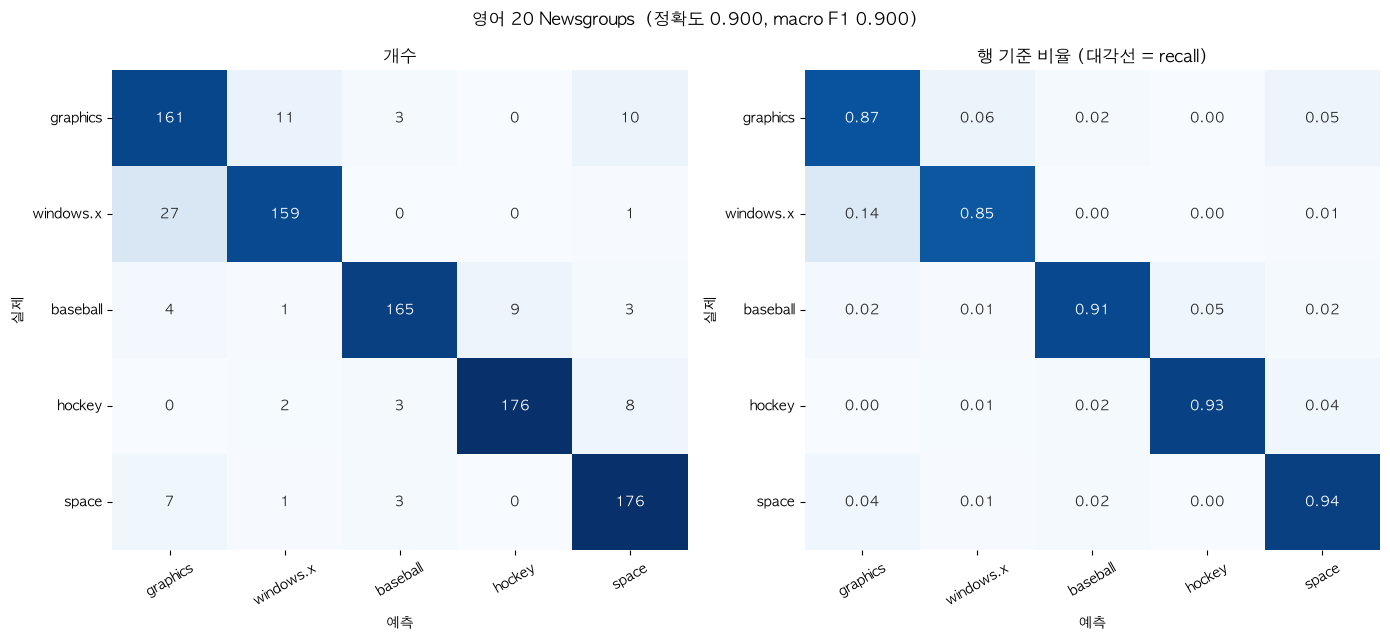

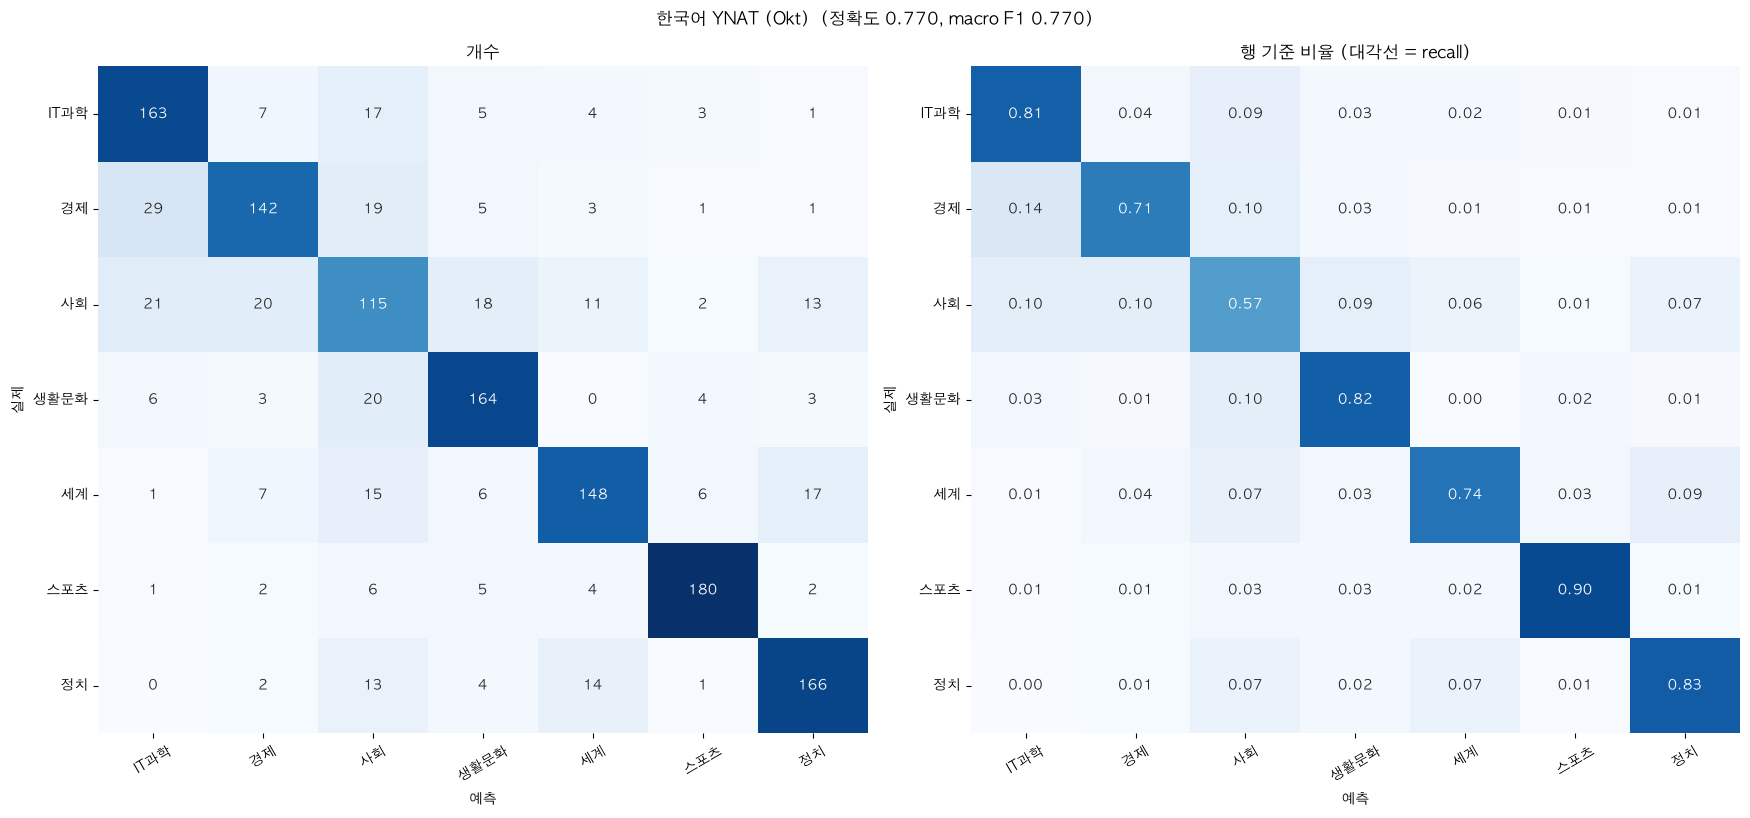

저장: ['confusion_matrix_en.png', 'confusion_matrix_ko-okt.png']


In [8]:
set_korean_font()


def plot_confusion(r, names, title, path):
    cm = confusion_matrix(r.test["label"], r.y_pred, labels=r.labels)
    ratio = cm / cm.sum(axis=1, keepdims=True)
    size = 0.9 * len(names) + 2
    fig, axes = plt.subplots(1, 2, figsize=(2 * size + 1, size))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=names, yticklabels=names, cbar=False)
    sns.heatmap(ratio, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1],
                xticklabels=names, yticklabels=names, cbar=False)
    for ax, sub in zip(axes, ["개수", "행 기준 비율 (대각선 = recall)"]):
        ax.set_title(sub)
        ax.set_xlabel("예측")
        ax.set_ylabel("실제")
        ax.tick_params(axis="y", rotation=0)
        ax.tick_params(axis="x", rotation=30)
    fig.suptitle(f"{title}  (정확도 {r.accuracy:.3f}, macro F1 {r.f1_macro:.3f})")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return cm


cm_en = plot_confusion(res["en"], short, "영어 20 Newsgroups", WORK / "confusion_matrix_en.png")
cm_ko = plot_confusion(res["ko-okt"], res["ko-okt"].labels, "한국어 YNAT (Okt)", WORK / "confusion_matrix_ko-okt.png")
print("저장:", sorted(p.name for p in WORK.glob("*.png")))

## 19.7 결과 해석: 어떤 카테고리끼리 헷갈리나

In [9]:
r_ko = res["ko-okt"]
ratio_ko = cm_ko / cm_ko.sum(axis=1, keepdims=True)
recall_ko = pd.Series(np.diag(ratio_ko), index=r_ko.labels).sort_values()
print("한국어 카테고리별 recall (낮은 순):")
print(recall_ko.round(3).to_string())
print("\n한국어에서 가장 많이 헷갈린 방향:")
for n, a, b in top_confusions(cm_ko, r_ko.labels, k=6):
    print(f"  실제 {a:<5} → 예측 {b:<5} {n:>3}건 (실제 {a}의 {n / cm_ko[r_ko.labels.index(a)].sum():.0%})")
for a, b in [("정치", "세계"), ("세계", "정치")]:
    n = cm_ko[r_ko.labels.index(a), r_ko.labels.index(b)]
    print(f"  실제 {a} → 예측 {b}: {n}건 (실제 {a}의 {n / cm_ko[r_ko.labels.index(a)].sum():.0%})")
col = r_ko.labels.index("사회")
print(f"\n'사회'로 예측된 문서 {cm_ko[:, col].sum()}건 중 실제 사회 {cm_ko[col, col]}건")

한국어 카테고리별 recall (낮은 순):
사회      0.575
경제      0.710
세계      0.740
IT과학    0.815
생활문화    0.820
정치      0.830
스포츠     0.900

한국어에서 가장 많이 헷갈린 방향:
  실제 경제    → 예측 IT과학   29건 (실제 경제의 14%)
  실제 사회    → 예측 IT과학   21건 (실제 사회의 10%)
  실제 생활문화  → 예측 사회     20건 (실제 생활문화의 10%)
  실제 사회    → 예측 경제     20건 (실제 사회의 10%)
  실제 경제    → 예측 사회     19건 (실제 경제의 10%)
  실제 사회    → 예측 생활문화   18건 (실제 사회의 9%)
  실제 정치 → 예측 세계: 14건 (실제 정치의 7%)
  실제 세계 → 예측 정치: 17건 (실제 세계의 8%)

'사회'로 예측된 문서 205건 중 실제 사회 115건


**영어**
- 오분류의 가장 큰 몫이 **graphics ↔ windows.x** 사이에서 나옵니다(19.2). 두 게시판 모두 컴퓨터 게시판이라 `file`, `program`, `display`, `image` 같은 어휘를 공유합니다. 특히 windows.x 글이 graphics로 가는 쪽이 많습니다.
- baseball ↔ hockey는 같은 스포츠지만 그보다 덜 헷갈립니다. 선수 이름, 팀 이름, `pitcher`, `goalie` 같은 종목 고유 어휘가 뚜렷하기 때문입니다.

**한국어**
- **사회**의 recall이 가장 낮습니다. 사회 기사는 경제, IT과학, 생활문화 쪽으로 흩어지고, 다른 주제의 기사도 사회로 많이 끌려옵니다. 사건·사고·교육·노동처럼 범위가 넓고 **고유 어휘가 적은 범주**이기 때문입니다.
- 스포츠는 `경기`, `감독`, 선수 이름처럼 고유 어휘가 뚜렷해 가장 잘 맞힙니다.
- **경제 → IT과학**이 가장 많은 단일 혼동이고, 정치 ↔ 세계도 서로 7~9%씩 헷갈립니다. 기업 기사(갤럭시 판매량은 경제인가 IT인가), 외교 기사(외국 정상의 방한은 정치인가 세계인가)처럼 **주제 경계 자체가 모호한** 경우입니다. 20장에서 사례로 확인합니다.

### 과제 형식으로 보고하기

In [10]:
for name, r in res.items():
    print("=== 분류 성능 평가 ===")
    print("모델: Logistic Regression (C=1.0, max_iter=2000)")
    print(f"데이터: {name}, Train {len(r.train):,} / Test {len(r.test):,}, 어휘 {len(r.vec.vocabulary_):,}")
    print(f"정확도: {r.accuracy:.3f}")
    print(f"F1-Score (macro): {r.f1_macro:.3f}\n")

=== 분류 성능 평가 ===
모델: Logistic Regression (C=1.0, max_iter=2000)
데이터: en, Train 3,716 / Test 930, 어휘 11,488
정확도: 0.900
F1-Score (macro): 0.900

=== 분류 성능 평가 ===
모델: Logistic Regression (C=1.0, max_iter=2000)
데이터: ko-okt, Train 5,600 / Test 1,400, 어휘 5,482
정확도: 0.770
F1-Score (macro): 0.770

=== 분류 성능 평가 ===
모델: Logistic Regression (C=1.0, max_iter=2000)
데이터: ko-whitespace, Train 5,598 / Test 1,400, 어휘 5,184
정확도: 0.706
F1-Score (macro): 0.710



## 📝 리포트용 정리: 분류 성능

| 데이터 | Train / Test | 정확도 | F1 (macro) | 해석 |
|---|---|---|---|---|
| 영어 20NG (5개) | 위 출력 | 위 출력 | 위 출력 | 오분류는 graphics ↔ windows.x에 집중 |
| 한국어 YNAT, Okt (7개) | 위 출력 | 위 출력 | 위 출력 | 사회 recall이 가장 낮음, 경계가 모호한 주제 쌍 존재 |
| 한국어 YNAT, 공백 | 위 출력 | 위 출력 | 위 출력 | Okt보다 낮음 (9장의 OOV 증가) |

표에는 위 셀의 출력 숫자를 그대로 옮기고, 혼동 행렬 그림을 함께 넣습니다. 17장의 시드 변동 폭도 한 줄 덧붙입니다.

## ✍️ 실습: 혼동 행렬에서 macro F1 계산하기

혼동 행렬(`np.ndarray`)만 받아 macro F1을 돌려주는 `macro_f1_from_cm(cm)`을 작성하세요. 어떤 카테고리로도 예측되지 않아 precision의 분모가 0이 되는 경우에는 그 카테고리의 F1을 0으로 둡니다. `cm_ko`에 적용해 sklearn의 macro F1과 같은지 확인하고, 아래 `cm_edge`에도 적용해 보세요.

In [11]:
cm_edge = np.array([[5, 0, 0],
                    [3, 0, 0],      # 두 번째 카테고리는 한 번도 예측되지 않았다
                    [1, 0, 4]])

In [12]:
# 여기에 작성하세요

**정답**

In [13]:
def macro_f1_from_cm(cm: np.ndarray) -> float:
    tp = np.diag(cm).astype(float)
    pred_total = cm.sum(axis=0)
    true_total = cm.sum(axis=1)
    precision = np.divide(tp, pred_total, out=np.zeros_like(tp), where=pred_total > 0)
    recall = np.divide(tp, true_total, out=np.zeros_like(tp), where=true_total > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return float(f1.mean())


print(f"직접 {macro_f1_from_cm(cm_ko):.4f} | sklearn {res['ko-okt'].f1_macro:.4f}")
print(f"cm_edge → {macro_f1_from_cm(cm_edge):.4f}")

직접 0.7702 | sklearn 0.7702
cm_edge → 0.5344


## 🧐 퀴즈

**Q1.** 혼동 행렬에서 "하키" 열의 합이 200이고 그중 대각선 칸이 180이면, 하키의 precision은? 이 숫자의 의미는?
<details><summary>▶ 정답 보기</summary>

$180 / 200 = 0.9$. 모델이 "하키"라고 예측한 문서 중 90%가 실제 하키라는 뜻입니다. 나머지 20건은 다른 카테고리를 하키로 잘못 예측한 것(FP)입니다.
</details>

**Q2.** 어떤 카테고리의 precision은 높은데 recall이 낮다면 모델은 어떻게 행동하고 있나요?
<details><summary>▶ 정답 보기</summary>

그 카테고리라고 말할 때는 대부분 맞지만, 그 카테고리 문서를 많이 놓치고 있습니다(조심스럽게 예측). 놓친 문서가 어느 카테고리로 갔는지는 혼동 행렬의 그 행을 보면 알 수 있습니다.
</details>

**Q3.** macro F1과 weighted F1이 크게 다르다면 무엇을 의심할 수 있나요?
<details><summary>▶ 정답 보기</summary>

카테고리 크기가 많이 다르고, 작은 카테고리의 성능이 큰 카테고리와 크게 다르다는 뜻입니다. 보통 작은 카테고리를 잘 못 맞혀서 macro F1이 더 낮게 나옵니다.
</details>

**Q4.** 행 기준 비율 히트맵의 대각선 값은 어떤 지표와 같나요?
<details><summary>▶ 정답 보기</summary>

카테고리별 recall입니다. 각 행을 실제 문서 수(행 합)로 나눴으므로 대각선은 "실제 그 카테고리 중 맞힌 비율"입니다.
</details>

## ✅ 체크포인트
- [ ] 정확도만으로 부족한 예를 들 수 있다.
- [ ] 혼동 행렬의 행·열·대각선을 읽고 가장 많이 헷갈리는 쌍을 찾을 수 있다.
- [ ] TP, FP, FN으로 precision, recall, F1을 손으로 계산할 수 있다.
- [ ] macro, weighted, micro 평균의 차이를 말할 수 있다.
- [ ] 혼동 행렬 그림을 저장하고 결과를 과제 형식으로 보고할 수 있다.

## 🔗 과제 연결과 다음 장
- 정확도·F1과 혼동 행렬 그림은 README "검증/실험 결과"의 필수 항목입니다. 프로젝트에서는 `outputs/<데이터>/`에 `confusion_matrix.png`와 `classification_report.txt`로 저장합니다.
- **20장. 오분류 분석**에서 틀린 문서를 하나씩 열어 보고, 단어별 기여도로 원인을 찾아 BoW의 한계와 연결합니다.